In [ ]:
!nvidia-smi
!pip -q install ultralytics

Mon Nov  9 20:52:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import zipfile

archive = Path("/content/drive/MyDrive/Colab Notebooks/YOLO.zip")
destination = Path("/content/datasets")

assert archive.exists(), f"Архив не найден: {archive}"

with zipfile.ZipFile(archive) as z:
    z.extractall(destination)

print("Распаковано в:", destination)
print("Содержимое:", [p.name for p in destination.iterdir()])

Распаковано в: /content/datasets
Содержимое: ['YOLO']


In [ ]:
from pathlib import Path
import yaml

root = Path("/content/datasets/YOLO")
assert root.is_dir(), f"Не найдена папка: {root}"


classes = (root / "classes.txt").read_text(
    encoding="utf-8-sig"
).splitlines()
assert classes, "classes.txt пуст"


for folder in ["images/train", "images/val"]:
    assert (root / folder).is_dir(), f"Не найдена папка: {root / folder}"

config = {
    "path": str(root),
    "train": "images/train",
    "val": "images/val",
    "names": {i: name.strip() for i, name in enumerate(classes)},
}

if (root / "images/test").is_dir():
    config["test"] = "images/test"

data_path = root / "data.yaml"


if data_path.exists():
    backup = root / "data.original.yaml"
    if not backup.exists():
        backup.write_bytes(data_path.read_bytes())

data_path.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

print(data_path.read_text())

path: /content/datasets/YOLO
train: images/train
val: images/val
names:
  0: box_hitech
test: images/test



In [ ]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO
import torch

data_path = Path("/content/datasets/YOLO/data.yaml")

assert data_path.exists(), f"Не найден файл: {data_path}"
assert torch.cuda.is_available(), "Включите GPU в настройках Colab"
assert Path("/content/drive/MyDrive").is_dir(), "Сначала подключите Google Drive"

print("GPU:", torch.cuda.get_device_name(0))
print("Конфигурация датасета:")
print(data_path.read_text())

run_name = "boxes_" + datetime.now().strftime("%Y%m%d_%H%M%S")
project = "/content/drive/MyDrive/yolo_boxes"

model = YOLO("yolo11n.pt")

model.train(
    data=str(data_path),
    epochs=100,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project=project,
    name=run_name,
    patience=20,
    seed=42,
    plots=True,
)

run_dir = Path(model.trainer.save_dir)
best_path = run_dir / "weights/best.pt"

print("Лучшая модель:", best_path)
print("Папка результатов:", run_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Конфигурация датасета:
path: /content/datasets/YOLO
train: images/train
val: images/val
names:
  0: box_hitech
test: images/test

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn

Лучшая модель: /content/drive/MyDrive/yolo_boxes/boxes_20261109_211959/weights/best.pt


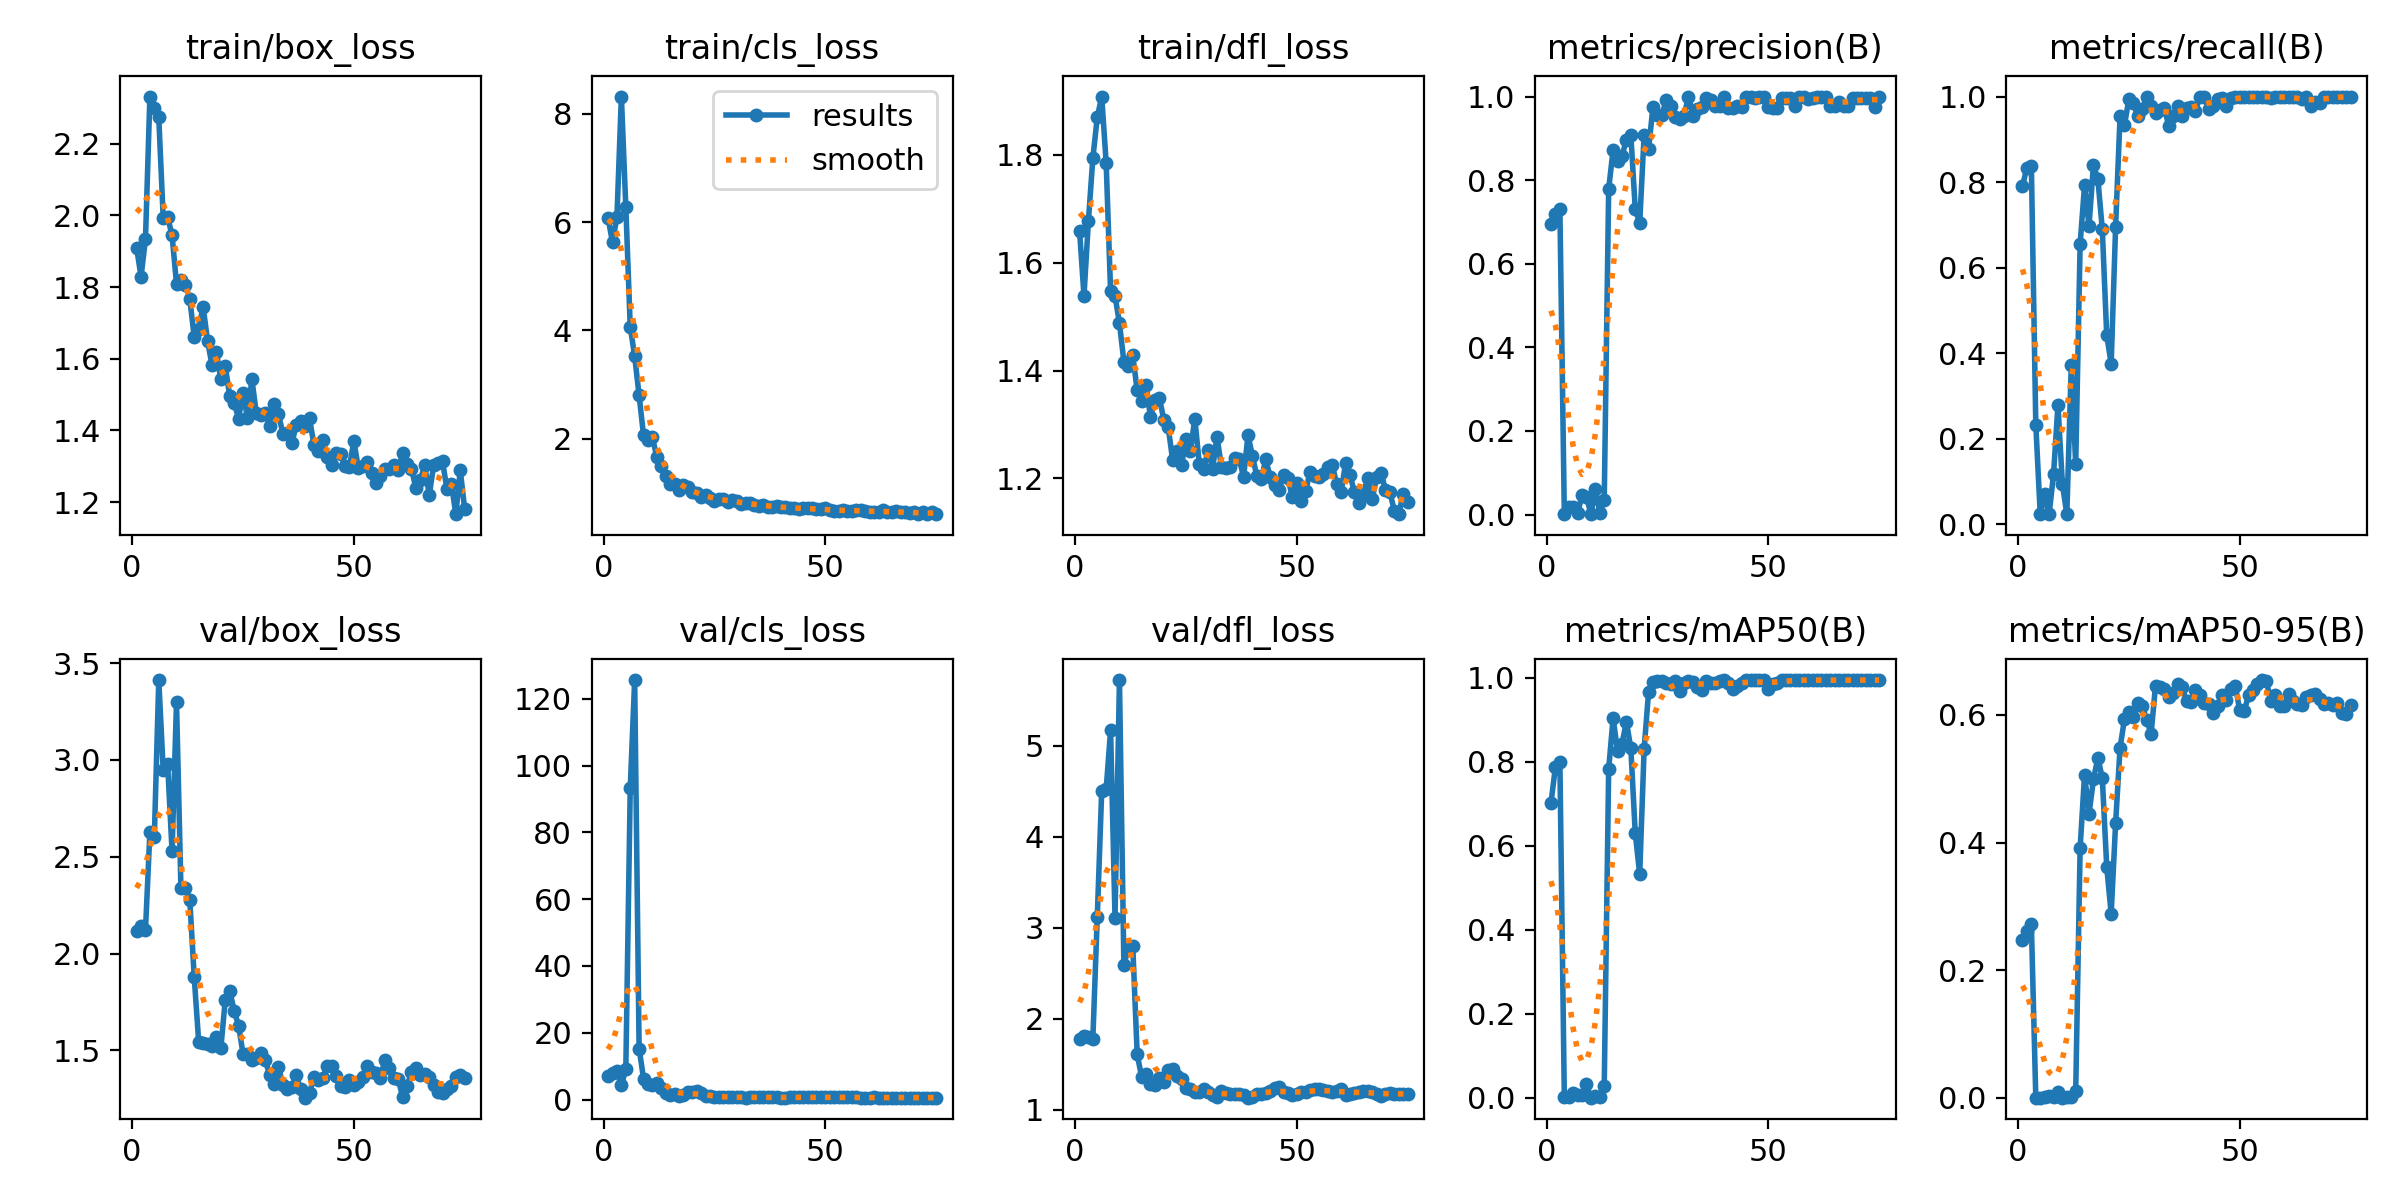

In [10]:
from IPython.display import display, Image

print("Лучшая модель:", best_path)

# Графики обучения
display(Image(filename=str(run_dir / "results.png")))

In [11]:
from ultralytics import YOLO

best = YOLO(str(best_path))

# Используем test, если он есть, иначе val
root = data_path.parent
images_dir = root / "images/test"

if not images_dir.is_dir() or not any(images_dir.iterdir()):
    images_dir = root / "images/val"

# stream=True позволяет обрабатывать картинки по очереди
for result in best.predict(
    source=str(images_dir),
    conf=0.25,
    device=0,
    save=True,          # картинки с рамками
    show_labels=True,   # название класса
    show_conf=True,     # уверенность
    save_txt=True,      # координаты найденных объектов
    save_conf=True,     # уверенность в текстовых файлах
    project=str(run_dir),
    name="detections",
    exist_ok=True,
    stream=True,
):
    pass

print("Веса:", best_path)
print("Картинки:", run_dir / "detections")


image 1/16 /content/datasets/YOLO/images/test/e95b55c8-photo_20261109_101432_438751.jpg: 480x640 2 box_hitechs, 10.9ms
image 2/16 /content/datasets/YOLO/images/test/ea70e0a3-photo_20261109_101302_403104.jpg: 480x640 4 box_hitechs, 32.0ms
image 3/16 /content/datasets/YOLO/images/test/ed25f4f7-photo_20261109_101431_427633.jpg: 480x640 3 box_hitechs, 23.9ms
image 4/16 /content/datasets/YOLO/images/test/ee7a0332-photo_20261109_101441_450470.jpg: 480x640 3 box_hitechs, 26.3ms
image 5/16 /content/datasets/YOLO/images/test/f042de37-photo_20261109_101333_428495.jpg: 480x640 2 box_hitechs, 18.6ms
image 6/16 /content/datasets/YOLO/images/test/f1296c5d-photo_20261109_101356_423258.jpg: 480x640 1 box_hitech, 27.9ms
image 7/16 /content/datasets/YOLO/images/test/f3aea2b1-photo_20261109_101443_449234.jpg: 480x640 4 box_hitechs, 13.3ms
image 8/16 /content/datasets/YOLO/images/test/f4ec7e30-photo_20261109_101309_435836.jpg: 480x640 1 box_hitech, 13.7ms
image 9/16 /content/datasets/YOLO/images/test/f7d